FIRST-ORDER LOGIC (FOL) RESOLUTION PROVER (CNF)
1. Variables start with lowercase (e.g., x, y, z)
2. Constants start with UPPERCASE (e.g., John, Peanuts, Anil)
3. Use '~' for NOT and '|' for OR

Press 1 for Default Example (John & Peanuts) or 2 for custom problem: ~allergies(x) | sneezes(x)

Enter Knowledge Base clauses in CNF (type 'done' when finished):
Clause 1: ~allergies(x) | sneezes(x)
Clause 2: ~livesWith(y, z) | ~cat(z) | ~allergicToCats(y) | allergies(y)
Clause 3: cat(Tom)
Clause 4: allergicToCats(Mary)
Clause 5: livesWith(Mary, Tom)
Clause 6: done

Enter Query to prove: sneezes(Mary)


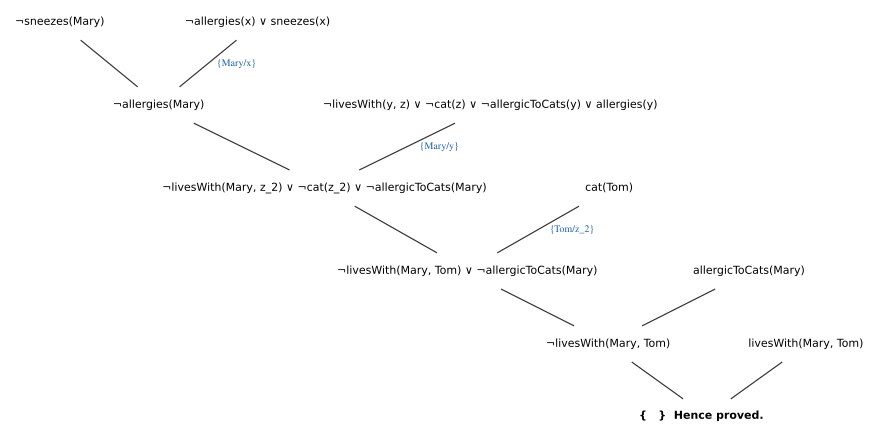

In [9]:
import heapq
import re
from graphviz import Digraph
from IPython.display import display


class Literal:

  def __init__(self, predicate, args, negated=False):
    self.predicate = predicate
    self.args = args
    self.negated = negated

  def negate(self):
    return Literal(self.predicate, self.args[:], not self.negated)

  def __repr__(self):
    neg_str = "¬" if self.negated else ""
    return f"{neg_str}{self.predicate}({', '.join(self.args)})"

  def __eq__(self, other):
    return (
        self.predicate == other.predicate
        and self.args == other.args
        and self.negated == other.negated
    )

  def __hash__(self):
    return hash((self.predicate, tuple(self.args), self.negated))


def is_variable(term):
  return isinstance(term, str) and term.islower()


def base_name(var):
  return re.sub(r"_\d+$", "", var)


def parse_literal(lit_str):
  lit_str = lit_str.strip()
  negated = False
  if lit_str.startswith("~") or lit_str.startswith("¬"):
    negated = True
    lit_str = lit_str[1:].strip()

  match = re.match(r"([A-Za-z0-9_]+)\(([^)]+)\)", lit_str)
  if not match:
    raise ValueError(f"Invalid literal format: '{lit_str}'")

  predicate = match.group(1).strip()
  args = [arg.strip() for arg in match.group(2).split(",")]
  return Literal(predicate, args, negated)


def parse_clause(clause_str):
  parts = re.split(r"\s*\|\s*|\s+V\s+", clause_str.strip())
  return [parse_literal(p) for p in parts if p.strip()]


def format_clause(clause):
  if not clause:
    return "{   }  Hence proved."
  cleaned = []
  for lit in clause:
    clean_args = [
        base_name(arg) if is_variable(arg) else arg for arg in lit.args
    ]
    cleaned.append(str(Literal(lit.predicate, clean_args, lit.negated)))
  return " ∨ ".join(cleaned)


def canonical_form(clause):
  mapping = {}
  counter = 0
  canon = []
  for lit in sorted(
      clause, key=lambda l: (l.predicate, l.negated, len(l.args))
  ):
    new_args = []
    for arg in lit.args:
      if is_variable(arg):
        if arg not in mapping:
          mapping[arg] = f"v{counter}"
          counter += 1
        new_args.append(mapping[arg])
      else:
        new_args.append(arg)
    canon.append((lit.predicate, lit.negated, tuple(new_args)))
  return tuple(sorted(canon))


def is_tautology(clause):
  for i in range(len(clause)):
    for j in range(i + 1, len(clause)):
      if (
          clause[i].predicate == clause[j].predicate
          and clause[i].args == clause[j].args
          and clause[i].negated != clause[j].negated
      ):
        return True
  return False


def unify_var(var, x, theta):
  if var in theta:
    return unify(theta[var], x, theta)
  elif is_variable(x) and x in theta:
    return unify(var, theta[x], theta)
  elif occurs_check(var, x, theta):
    return None
  else:
    theta[var] = x
    return theta


def occurs_check(var, x, theta):
  if var == x:
    return True
  elif is_variable(x) and x in theta:
    return occurs_check(var, theta[x], theta)
  return False


def unify(x, y, theta):
  if theta is None:
    return None
  elif x == y:
    return theta
  elif is_variable(x):
    return unify_var(x, y, theta)
  elif is_variable(y):
    return unify_var(y, x, theta)
  elif isinstance(x, list) and isinstance(y, list):
    if len(x) != len(y):
      return None
    for a, b in zip(x, y):
      theta = unify(a, b, theta)
      if theta is None:
        return None
    return theta
  else:
    return None


def apply_substitution(clause, theta):
  new_clause = []
  for lit in clause:
    new_args = []
    for arg in lit.args:
      val = arg
      while is_variable(val) and val in theta:
        val = theta[val]
      new_args.append(val)
    new_lit = Literal(lit.predicate, new_args, lit.negated)
    if new_lit not in new_clause:
      new_clause.append(new_lit)
  return new_clause


def standardize_variables(clause, counter):
  mapping = {}
  new_clause = []
  for lit in clause:
    new_args = []
    for arg in lit.args:
      if is_variable(arg):
        if arg not in mapping:
          mapping[arg] = f"{arg}_{counter}"
        new_args.append(mapping[arg])
      else:
        new_args.append(arg)
    new_clause.append(Literal(lit.predicate, new_args, lit.negated))
  return new_clause


def resolve(ci, cj):
  resolvents = []
  for li in ci:
    for lj in cj:
      if li.predicate == lj.predicate and li.negated != lj.negated:
        theta = unify(li.args, lj.args, {})
        if theta is not None:
          new_ci = [l for l in ci if l != li]
          new_cj = [l for l in cj if l != lj]
          combined = apply_substitution(new_ci + new_cj, theta)
          resolvents.append((combined, theta))
  return resolvents


def draw_resolution_tree(clauses_info, goal_idx):
  dot = Digraph(format="png")
  dot.attr(rankdir="TB", splines="line", nodesep="0.6", ranksep="0.5")
  dot.attr(
      "node", shape="plaintext", fontname="DejaVu Sans", fontsize="11"
  )
  dot.attr("edge", arrowhead="none", color="#333333", penwidth="1.2")

  visited = set()

  def add_nodes(idx):
    if idx in visited:
      return
    visited.add(idx)

    info = clauses_info[idx]
    label = format_clause(info["clause"])
    if idx == goal_idx:
      dot.node(str(idx), f"<<B>{label}</B>>")
    else:
      dot.node(str(idx), label)

    if info["parents"] is not None:
      p1, p2 = info["parents"]
      if clauses_info[p1]["parents"] is not None:
        left, right = p1, p2
      else:
        left, right = p2, p1

      add_nodes(left)
      add_nodes(right)

      sub = info["sub"]
      sub_label = ""
      if sub:
        pairs = [f"{v}/{k}" for k, v in sub.items()]
        sub_label = "  {" + ", ".join(pairs) + "}"

      dot.edge(str(left), str(idx))
      dot.edge(str(right), str(idx), label=sub_label, fontsize="10", fontcolor="#1a5fb4")

  add_nodes(goal_idx)
  display(dot)


def fol_resolution(kb_clauses, query_literal):
  clauses_info = []
  seen_canons = set()
  sos_indices = set()

  for idx, c in enumerate(kb_clauses):
    std_c = standardize_variables(c, idx + 1)
    canon = canonical_form(std_c)
    if canon not in seen_canons:
      seen_canons.add(canon)
      clauses_info.append({
          "clause": std_c,
          "parents": None,
          "sub": None,
          "source": "Given KB",
      })

  neg_query = [query_literal.negate()]
  query_idx = len(clauses_info)
  clauses_info.append({
      "clause": neg_query,
      "parents": None,
      "sub": None,
      "source": "Negated Query",
  })
  seen_canons.add(canonical_form(neg_query))
  sos_indices.add(query_idx)

  pq = []
  for i in range(query_idx):
    priority = len(clauses_info[i]["clause"]) + len(neg_query)
    heapq.heappush(pq, (priority, i, query_idx))

  visited_pairs = set()

  while pq:
    _, i, j = heapq.heappop(pq)
    pair = (min(i, j), max(i, j))
    if pair in visited_pairs:
      continue
    visited_pairs.add(pair)

    resolvents = resolve(clauses_info[i]["clause"], clauses_info[j]["clause"])
    for resolvent, theta in resolvents:
      if is_tautology(resolvent):
        continue

      clean_theta = {}
      for k, v in theta.items():
        val = v
        while is_variable(val) and val in theta:
          val = theta[val]
        clean_k = base_name(k)
        clean_v = base_name(val) if is_variable(val) else val
        if clean_k != clean_v:
          clean_theta[clean_k] = clean_v

      if len(resolvent) == 0:
        goal_idx = len(clauses_info)
        clauses_info.append({
            "clause": [],
            "parents": (i, j),
            "sub": clean_theta,
            "source": "Derived",
        })
        draw_resolution_tree(clauses_info, goal_idx)
        return True

      canon = canonical_form(resolvent)
      if canon not in seen_canons:
        seen_canons.add(canon)
        new_idx = len(clauses_info)
        std_res = standardize_variables(resolvent, new_idx + 1)
        clauses_info.append({
            "clause": std_res,
            "parents": (i, j),
            "sub": clean_theta,
            "source": "Derived",
        })
        sos_indices.add(new_idx)

        for k in range(new_idx):
          if k in sos_indices or k < query_idx:
            priority = len(clauses_info[k]["clause"]) + len(std_res)
            heapq.heappush(pq, (priority, k, new_idx))

  print("\nCannot prove: Empty clause could not be derived.")
  return False


def run_solver():
  print("FIRST-ORDER LOGIC (FOL) RESOLUTION PROVER (CNF)")
  print("1. Variables start with lowercase (e.g., x, y, z)")
  print("2. Constants start with UPPERCASE (e.g., John, Peanuts, Anil)")
  print("3. Use '~' for NOT and '|' for OR")

  choice = input(
      "\nPress 1 for Default Example (John & Peanuts) or 2 for custom problem: "
  ).strip()

  if choice == "1":
    raw_kb = [
        "~food(x) | likes(John, x)",
        "food(Apple)",
        "food(Vegetables)",
        "~eats(y, z) | killed(y) | food(z)",
        "eats(Anil, Peanuts)",
        "alive(Anil)",
        "~eats(Anil, w) | eats(Harry, w)",
        "killed(g) | alive(g)",
        "~alive(k) | ~killed(k)",
    ]
    raw_query = "likes(John, Peanuts)"

  else:
    print("\nEnter Knowledge Base clauses in CNF (type 'done' when finished):")
    raw_kb = []
    while True:
      line = input(f"Clause {len(raw_kb)+1}: ").strip()
      if line.lower() == "done":
        break
      if line:
        raw_kb.append(line)

    raw_query = input("\nEnter Query to prove: ").strip()

  try:
    kb_clauses = [parse_clause(c) for c in raw_kb]
    query_lit = parse_literal(raw_query)
    fol_resolution(kb_clauses, query_lit)
  except Exception as e:
    print(f"\nError parsing input: {e}")


run_solver()


In [17]:
import itertools
import re


class Expr:
  pass


class Pred(Expr):

  def __init__(self, n, a):
    self.name, self.args = n, a

  def __repr__(self):
    return f"{self.name}({', '.join(self.args)})"


class Not(Expr):

  def __init__(self, e):
    self.expr = e

  def __repr__(self):
    return (
        f"¬[{self.expr}]"
        if isinstance(self.expr, (And, Or, Imp, Iff, ForAll, Exists))
        else f"¬{self.expr}"
    )


class And(Expr):

  def __init__(self, l, r):
    self.left, self.right = l, r

  def __repr__(self):
    l = f"[{self.left}]" if isinstance(self.left, (Or, Imp, Iff)) else f"{self.left}"
    r = f"[{self.right}]" if isinstance(self.right, (Or, Imp, Iff)) else f"{self.right}"
    return f"{l} ∧ {r}"


class Or(Expr):

  def __init__(self, l, r):
    self.left, self.right = l, r

  def __repr__(self):
    l = f"[{self.left}]" if isinstance(self.left, (Imp, Iff)) else f"{self.left}"
    r = f"[{self.right}]" if isinstance(self.right, (Imp, Iff)) else f"{self.right}"
    return f"{l} ∨ {r}"


class Imp(Expr):

  def __init__(self, l, r):
    self.left, self.right = l, r

  def __repr__(self):
    l = f"[{self.left}]" if isinstance(self.left, (Imp, Iff, ForAll, Exists)) else f"{self.left}"
    r = f"[{self.right}]" if isinstance(self.right, (Imp, Iff, ForAll, Exists)) else f"{self.right}"
    return f"{l} ⇒ {r}"


class Iff(Expr):

  def __init__(self, l, r):
    self.left, self.right = l, r

  def __repr__(self):
    return f"[{self.left}] ⇔ [{self.right}]"


class ForAll(Expr):

  def __init__(self, v, e):
    self.var, self.expr = v, e

  def __repr__(self):
    return (
        f"∀{self.var} [{self.expr}]"
        if isinstance(self.expr, (And, Or, Imp, Iff))
        else f"∀{self.var} {self.expr}"
    )


class Exists(Expr):

  def __init__(self, v, e):
    self.var, self.expr = v, e

  def __repr__(self):
    return (
        f"∃{self.var} [{self.expr}]"
        if isinstance(self.expr, (And, Or, Imp, Iff))
        else f"∃{self.var} {self.expr}"
    )


class Parser:

  def __init__(self, text):
    for k, v in [
        ("∀", " forall "),
        ("∃", " exists "),
        ("⇒", " -> "),
        ("⇔", " <-> "),
        ("∧", " & "),
        ("∨", " | "),
        ("¬", " ~ "),
        ("[", "("),
        ("]", ")"),
    ]:
      text = text.replace(k, v)
    self.tokens = re.findall(
        r"forall|exists|<->|->|[()~&|:,]|[A-Za-z0-9_]+", text
    )
    self.pos = 0

  def peek(self):
    return self.tokens[self.pos] if self.pos < len(self.tokens) else None

  def consume(self, exp=None):
    tok = self.peek()
    if exp and tok != exp:
      raise ValueError(f"Expected '{exp}', got '{tok}'")
    self.pos += 1
    return tok

  def parse(self):
    return self.parse_iff()

  def parse_iff(self):
    if self.peek() in ("forall", "exists"):
      cls = ForAll if self.consume() == "forall" else Exists
      var = self.consume()
      if self.peek() == ":":
        self.consume(":")
      return cls(var, self.parse_iff())
    n = self.parse_imp()
    while self.peek() == "<->":
      self.consume("<->")
      n = Iff(n, self.parse_imp())
    return n

  def parse_imp(self):
    n = self.parse_or()
    while self.peek() == "->":
      self.consume("->")
      n = Imp(n, self.parse_or())
    return n

  def parse_or(self):
    n = self.parse_and()
    while self.peek() in ("|", "V"):
      self.consume()
      n = Or(n, self.parse_and())
    return n

  def parse_and(self):
    n = self.parse_unary()
    while self.peek() in ("&", "^"):
      self.consume()
      n = And(n, self.parse_unary())
    return n

  def parse_unary(self):
    if self.peek() == "~":
      self.consume("~")
      return Not(self.parse_unary())
    return self.parse_atom()

  def parse_atom(self):
    if self.peek() == "(":
      self.consume("(")
      n = self.parse_iff()
      self.consume(")")
      return n
    name = self.consume()
    self.consume("(")
    args = [self.consume()]
    while self.peek() == ",":
      self.consume(",")
      args.append(self.consume())
    self.consume(")")
    return Pred(name, args)


def elim_imp(e):
  if isinstance(e, Pred):
    return e
  if isinstance(e, Not):
    return Not(elim_imp(e.expr))
  if isinstance(e, (And, Or)):
    return type(e)(elim_imp(e.left), elim_imp(e.right))
  if isinstance(e, Imp):
    return Or(Not(elim_imp(e.left)), elim_imp(e.right))
  if isinstance(e, Iff):
    a, b = elim_imp(e.left), elim_imp(e.right)
    return And(Or(Not(a), b), Or(Not(b), a))
  return type(e)(e.var, elim_imp(e.expr))


def move_not(e):
  if isinstance(e, Pred):
    return e
  if isinstance(e, (And, Or)):
    return type(e)(move_not(e.left), move_not(e.right))
  if isinstance(e, (ForAll, Exists)):
    return type(e)(e.var, move_not(e.expr))
  if isinstance(e, Not):
    i = e.expr
    if isinstance(i, Not):
      return move_not(i.expr)
    if isinstance(i, And):
      return Or(move_not(Not(i.left)), move_not(Not(i.right)))
    if isinstance(i, Or):
      return And(move_not(Not(i.left)), move_not(Not(i.right)))
    if isinstance(i, ForAll):
      return Exists(i.var, move_not(Not(i.expr)))
    if isinstance(i, Exists):
      return ForAll(i.var, move_not(Not(i.expr)))
    return Not(move_not(i))


def std_vars(e, used=None, m=None, pool=None):
  used = used if used is not None else set()
  m = m or {}
  pool = pool or iter("xyzwuvpqrs")
  if isinstance(e, Pred):
    return Pred(e.name, [m.get(a, a) for a in e.args])
  if isinstance(e, Not):
    return Not(std_vars(e.expr, used, m, pool))
  if isinstance(e, (And, Or)):
    return type(e)(
        std_vars(e.left, used, m, pool), std_vars(e.right, used, m, pool)
    )
  v = e.var
  nv = next(x for x in pool if x not in used) if v in used else v
  used.add(nv)
  return type(e)(nv, std_vars(e.expr, used, dict(m, **{v: nv}), pool))


def skolemize(e, uvars=None, smap=None, cnt=None):
  uvars, smap, cnt = uvars or [], smap or {}, cnt or itertools.count(1)
  if isinstance(e, Pred):
    return Pred(e.name, [smap.get(a, a) for a in e.args])
  if isinstance(e, Not):
    return Not(skolemize(e.expr, uvars, smap, cnt))
  if isinstance(e, (And, Or)):
    return type(e)(
        skolemize(e.left, uvars, smap, cnt),
        skolemize(e.right, uvars, smap, cnt),
    )
  if isinstance(e, ForAll):
    return ForAll(e.var, skolemize(e.expr, uvars + [e.var], smap, cnt))
  idx = next(cnt)
  sk = f"F{idx}({', '.join(uvars)})" if uvars else f"G{idx}"
  return skolemize(e.expr, uvars, dict(smap, **{e.var: sk}), cnt)


def drop_univ(e):
  if isinstance(e, ForAll):
    return drop_univ(e.expr)
  if isinstance(e, Not):
    return Not(drop_univ(e.expr))
  if isinstance(e, (And, Or)):
    return type(e)(drop_univ(e.left), drop_univ(e.right))
  return e


def dist_or(e):
  if isinstance(e, And):
    return And(dist_or(e.left), dist_or(e.right))
  if isinstance(e, Or):
    a, b = dist_or(e.left), dist_or(e.right)
    if isinstance(a, And):
      return And(dist_or(Or(a.left, b)), dist_or(Or(a.right, b)))
    if isinstance(b, And):
      return And(dist_or(Or(a, b.left)), dist_or(Or(a, b.right)))
    return Or(a, b)
  return e


def split_clauses(e):
  return (
      split_clauses(e.left) + split_clauses(e.right)
      if isinstance(e, And)
      else [e]
  )


def convert_to_cnf(s):
  e0 = Parser(s).parse()
  e1 = elim_imp(e0)
  e2 = move_not(e1)
  e3 = std_vars(e2)
  e4 = skolemize(e3)
  e5 = drop_univ(e4)
  e6 = dist_or(e5)
  steps = [
      ("ORIGINAL FOL FORMULA:", e0),
      ("STEP 1: Eliminate Implications (⇒)", e1),
      ("STEP 2: Move Negation (¬) Inwards", e2),
      ("STEP 3: Standardize Variables Apart", e3),
      ("STEP 4: Skolemize Existential Quantifiers (∃)", e4),
      ("STEP 5: Drop Universal Quantifiers (∀)", e5),
      ("STEP 6: Distribute ∨ over ∧ (CNF)", e6),
  ]
  for title, expr in steps:
    print(f"\n{title}\n  {expr}")
  print("\nFINAL CLAUSAL FORM:")
  for i, c in enumerate(split_clauses(e6), 1):
    print(f"  Clause {i}: {c}")


ch = input("Press 1 for Default Formula or 2 for Custom Formula: ").strip()
f = (
    "∀x [∀y Animal(y) ⇒ Loves(x, y)] ⇒ [∃y Loves(y, x)]"
    if ch == "1"
    else input("Enter FOL formula: ").strip()
)
convert_to_cnf(f)


Press 1 for Default Formula or 2 for Custom Formula: 1

ORIGINAL FOL FORMULA:
  ∀x [[∀y [Animal(y) ⇒ Loves(x, y)]] ⇒ [∃y Loves(y, x)]]

STEP 1: Eliminate Implications (⇒)
  ∀x [¬[∀y [¬Animal(y) ∨ Loves(x, y)]] ∨ ∃y Loves(y, x)]

STEP 2: Move Negation (¬) Inwards
  ∀x [∃y [Animal(y) ∧ ¬Loves(x, y)] ∨ ∃y Loves(y, x)]

STEP 3: Standardize Variables Apart
  ∀x [∃y [Animal(y) ∧ ¬Loves(x, y)] ∨ ∃z Loves(z, x)]

STEP 4: Skolemize Existential Quantifiers (∃)
  ∀x [Animal(F1(x)) ∧ ¬Loves(x, F1(x)) ∨ Loves(F2(x), x)]

STEP 5: Drop Universal Quantifiers (∀)
  Animal(F1(x)) ∧ ¬Loves(x, F1(x)) ∨ Loves(F2(x), x)

STEP 6: Distribute ∨ over ∧ (CNF)
  [Animal(F1(x)) ∨ Loves(F2(x), x)] ∧ [¬Loves(x, F1(x)) ∨ Loves(F2(x), x)]

FINAL CLAUSAL FORM:
  Clause 1: Animal(F1(x)) ∨ Loves(F2(x), x)
  Clause 2: ¬Loves(x, F1(x)) ∨ Loves(F2(x), x)
